# Imports

In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np 
import scipy.stats as stats #(not in environment yet?)
import sys
from statsmodels.stats.multicomp import pairwise_tukeyhsd #(not in envirnoment yet)
import seaborn as sns
import pingouin as pg

# from statannotations.Annotator import Annotator

# Loading Data

## Looping over all datafiles and concatenating them

In [2]:

behav_data_path = "/mnt/home/bielefeldt/MPIB-SRT/879-multieyetem/behavioural_outputfiles"
sys.path.append(behav_data_path)

df_list = []
for file_name in os.listdir(behav_data_path):
    if file_name.endswith(".txt") and "pr.txt" not in file_name and not file_name.startswith("resultfile_pil"):  # Check if the file has .txt extension
        file_path = os.path.join(behav_data_path, file_name)
  
        # Read the file and determine whether to skip rows based on numerical content
        data = pd.read_table(file_path, skipinitialspace=True)
        has_numerical_content = data.applymap(lambda x: isinstance(x, (int, float))).any(axis=1)
        
        # Exclude rows with no numerical content
        data = data[has_numerical_content]
        
        df_list.append(data)

# Concatenate all DataFrames in the list
df = pd.concat(df_list, ignore_index=True)

/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/outdated/utils.py:14: OutdatedPackageWarning: The package pingouin is out of date. Your version is 0.5.3, the latest is 0.5.4.
Set the environment variable OUTDATED_IGNORE=1 to disable these warnings.
  return warn(


## Binomial Tests of Accuracy

### Binomial Test of All Conditions

In [3]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data = df.loc[df['subID'] == i, 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data)

    trials = len(participant_data)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion)
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print(f"  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.4948
  Correct Responses = 285 out of 576
  Binomial Test (k=285, n=576, p-value=0.8350)
  Interpretation: Not Significant
There were 1 elements in the results


### Binomial Test Condition 1

In [4]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data1.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data1)

    trials = len(participant_data1)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.4635
  Correct Responses = 89 out of 192
  Binomial Test (k=89, n=192, p-value=0.3482)
  Interpretation: Not Significant
There were 1 elements in the results


### Binomial Test Condition 2

In [5]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data2 = df.loc[(df['subID'] == i) & (df['items_presented'] == 2), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data2.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data2)

    trials = len(participant_data2)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# # Print or analyze the results
# for result in results:
#     participant_id, mean_accuracy, correct_responses, k, n, p_value = result
#     print(f"Participant {participant_id}:")
#     print(f"  Mean Accuracy = {mean_accuracy:.4f}")
#     print(f"  Correct Responses = {correct_responses} out of {n}")
#     print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
#     print("  Interpretation:", end=" ")
    
#     # Determine if the result is significant based on your alpha level
#     if p_value < alpha:
#         print("Significant")
#     else:
#         print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either


Participant OUGX64:
  Mean Accuracy = 0.5156
  Correct Responses = 99 out of 192
  Binomial Test (k=99, n=192, p-value=0.7183)
  Interpretation: Not Significant
Participant 6TQVJE:
  Mean Accuracy = 0.5677
  Correct Responses = 109 out of 192
  Binomial Test (k=109, n=192, p-value=0.0709)
  Interpretation: Not Significant
Participant 30K8XE:
  Mean Accuracy = 0.5521
  Correct Responses = 106 out of 192
  Binomial Test (k=106, n=192, p-value=0.1701)
  Interpretation: Not Significant
There were 3 elements in the results


### Binomial Test Condition 3

In [6]:
# Binomtest instead of binom_test

# Get unique participant IDs
partis = df['subID'].unique()

# Set the assumed accuracy (expected proportion)
expected_proportion = 0.5

# Set your significance level
alpha = 0.05

# Create a list to store results
results = []

## data to be exlccluded and other info:
# VHG934 missing in data
# which data to exclude because of version and triggers missing?
# Loop over each participant
for i in partis:
    # Get the data for the current participant
    participant_data3 = df.loc[(df['subID'] == i) & (df['items_presented'] == 3), 'acc_trial_concrete_cued']

    # Calculate the mean accuracy for the current participant
    mean_per_pp = participant_data3.mean()
    
    # Count the correct responses for the current participant
    correct_responses = sum(participant_data3)

    trials = len(participant_data3)
  
    # can maybe not use the p = anymore because the result of the new binomtest (instead of binom_test) is a variable of the type "BinomTestResult", which has all statical values in it. Maybe I can then just omit the 
    # results.append and also maybe omit the empty results matrix at the top
    binom_results = stats.binomtest(correct_responses, trials, p=expected_proportion, )
    k = binom_results.k
    n = binom_results.n
    p_value = binom_results.pvalue
    # print(binomresults)
    # print(binomresults.pvalue)
    # Store the results in a tuple (participant ID, mean accuracy, p-value)
    results.append((i, mean_per_pp, correct_responses, k, n, p_value))

# Print or analyze the results
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    print(f"Participant {participant_id}:")
    print(f"  Mean Accuracy = {mean_accuracy:.4f}")
    print(f"  Correct Responses = {correct_responses} out of {n}")
    print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
    print("  Interpretation:", end=" ")
    
    # Determine if the result is significant based on your alpha level
    if p_value < alpha:
        print("Significant")
    else:
        print("Not Significant")

result_len = 0
## List of the ones to be excluded
for result in results:
    participant_id, mean_accuracy, correct_responses, k, n, p_value = result
    if p_value > 0.05:
        result_len = result_len + 1
        print(f"Participant {participant_id}:")
        print(f"  Mean Accuracy = {mean_accuracy:.4f}")
        print(f"  Correct Responses = {correct_responses} out of {n}")
        print(f"  Binomial Test (k={k}, n={n}, p-value={p_value:.4f})")
        print("  Interpretation:", end=" ")
        
        # Determine if the result is significant based on your alpha level
        if p_value < alpha:
            print("Significant")
        else:
            print("Not Significant")
print(f'There were {result_len} elements in the results')

# In this case the result means that a participant that is not significant is not significantly different from the expected proportion or from chance level. They performed not better than chance level. However this would mean that performing significantly worse than chance level would not be exlcluded either

Participant Z16JQR:
  Mean Accuracy = 0.7448
  Correct Responses = 143 out of 192
  Binomial Test (k=143, n=192, p-value=0.0000)
  Interpretation: Significant
Participant C9A31N:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant LPULPG:
  Mean Accuracy = 0.7708
  Correct Responses = 148 out of 192
  Binomial Test (k=148, n=192, p-value=0.0000)
  Interpretation: Significant
Participant R8CW7K:
  Mean Accuracy = 0.7135
  Correct Responses = 137 out of 192
  Binomial Test (k=137, n=192, p-value=0.0000)
  Interpretation: Significant
Participant D62XJG:
  Mean Accuracy = 0.6354
  Correct Responses = 122 out of 192
  Binomial Test (k=122, n=192, p-value=0.0002)
  Interpretation: Significant
Participant XXRRPP:
  Mean Accuracy = 0.5573
  Correct Responses = 107 out of 192
  Binomial Test (k=107, n=192, p-value=0.1294)
  Interpretation: Not Significant
Participant ZGV9KP:
  Mean Accuracy = 0.67

## Adding Columns for later use

### Adding Column for mask

In [7]:
df['mask'] = 0

df.loc[df['onset_mask'].notna() & (df['onset_mask'] > 0), 'mask'] = 1

### Adding Column for Button Press

In [8]:
# There are no NANs in the button press column. What happens when no button was pressed? Probably they just get an inaccurate but this would not be seen in the data, without the trigger there would be no way of knowing whether it was inaccurate because no button was pressed or even though a button was pressed


# Calculate 'correct_rot_response'
df['correct_rot_response'] = df['object_cued_rot'] - df['object_test_rot_cued']

# Adding the new column with 0 and 1 values based on conditions
df['button_press_clockwise'] = 0  # Initialize with 0
# if the correct response is clockwise and the person was correct -> clockwise button press
df.loc[(df['correct_rot_response'] > 0) & (df['acc_trial_concrete_cued'] > 0), 'button_press_clockwise'] = 1
# if the correct response is anticlockwise and the person was not correct -> clockwise button press
df.loc[(df['correct_rot_response'] < 0) & (df['acc_trial_concrete_cued'] == 0), 'button_press_clockwise'] = 1

### Adding column for stimuli subset

In [9]:
# Define the stimuli sets
stimuli_set1 = ['01_pitcher02a_BOSS.jpg', '01_lighthouse.jpg', '01_table03.jpg']
stimuli_set2 = ['02_crown.jpg', '02_candelabra.jpg', '02_photoshopTelephone.jpg']
stimuli_set3 = ['03_gazebo.jpg', '03_radio03a.jpg', '03_lamppost01.jpg']

# Function to determine the stimuli set based on 'object_1_name'
def determine_stimuli_set(row):
    object_name = row['object_1_name']
    if object_name in stimuli_set1:
        return 'stimuli_set1'
    elif object_name in stimuli_set2:
        return 'stimuli_set2'
    elif object_name in stimuli_set3:
        return 'stimuli_set3'
    else:
        return 'Unknown' 

# Use the apply() method to create the 'stimuli_set' column
df['stimuli_set'] = df.apply(determine_stimuli_set, axis=1)

### Adding column for orientation bin

In [10]:
# Define the orientation bins and labels
orientation_bins = {
    11.25: 'Ori Bin A', 33.75: 'Ori Bin B', 56.25: 'Ori Bin C', 78.75: 'Ori Bin D',
    101.25: 'Ori Bin A', 123.75: 'Ori Bin B', 146.25: 'Ori Bin C', 168.75: 'Ori Bin D',
    191.25: 'Ori Bin A', 213.75: 'Ori Bin B', 236.25: 'Ori Bin C', 258.75: 'Ori Bin D',
    281.25: 'Ori Bin A', 303.75: 'Ori Bin B', 326.25: 'Ori Bin C', 348.75: 'Ori Bin D'
}

# Create a new column with bin labels
df['Orientation_Bin'] = df['object_cued_rot'].map(orientation_bins)


### Column names as variables

In [11]:
columns = df.columns
column_names = df.columns.tolist()

# Descriptive Statistics before Exclusion

In [12]:
# Number of participants *before* exclusion
len_partis = len(partis)
print(f'There were {len_partis} participants in the original dataset.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
sd_age = age_by_sub_id.std()
print(f'The mean age of participants was {mean_age:.2f} with the standard deviation of {sd_age:.2f}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 43 participants in the original dataset.
Count of male Participants: 12
Proportion of male participants: 0.27906976744186046
The mean age of participants was 25.53 with the standard deviation of 4.59
There were 21 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 15 with stimuli set 2, and 13 with stimuli set 3.


## Excluding Participants

In [13]:
# List of subject IDs to exclude

# excluding OUG64 for performance (binomial test)
# potentially excluding UCXTVD and D62XJG because they had the square mask

# subjects_to_exclude = ['OUGX64', 'UCXTVD', 'D62XJG']
subjects_to_exclude = ['OUGX64']

# Use boolean indexing to drop rows where 'subID' is in the exclusion list
df = df[~df['subID'].isin(subjects_to_exclude)]

good_partis = df['subID'].unique()

# Descriptive Statistics after Exclusion

In [14]:
# Number of participants after exclusion
good_partis = df['subID'].unique()
len_good_partis = len(good_partis)
print(f'There were {len_good_partis} participants in the dataset that went into the final analysis.')

# Gender
# Group the DataFrame by sub_ID and get the first occurrence of sub_gender in each group
gender_by_sub_id = df.groupby('subID')['sub_gender'].first()

# Count the instances of 'M' within the grouped sub_gender data
gender_counts = gender_by_sub_id.value_counts()
if 'M' in gender_counts:
    count_of_males = gender_counts['M']
    print(f"Count of male Participants: {count_of_males}")

# Calculate the proportion
gender_propo = count_of_males / len(good_partis)
print('Proportion of male participants:', gender_propo)

# age
age_by_sub_id = df.groupby('subID')['sub_age'].first()
mean_age = age_by_sub_id.mean()
print(f'The mean age of participants was: {mean_age}')

# number of participants with and without mask
masked_pp = df.groupby('subID')['mask'].first()
mask_counts = masked_pp.value_counts()
print(f"There were {mask_counts[1]} Participants that had the Version of the task including the mask and {mask_counts[0]} without the mask.")

# number of participants per stimuli set
stimset_pp = df.groupby('subID')['stimuli_set'].first()
stimset_counts = stimset_pp.value_counts()
print(f"There were {stimset_counts['stimuli_set1']} Participants tested with stimuli set 1, {stimset_counts['stimuli_set2']} with stimuli set 2, and {stimset_counts['stimuli_set3']} with stimuli set 3.")

There were 42 participants in the dataset that went into the final analysis.
Count of male Participants: 12
Proportion of male participants: 0.2857142857142857
The mean age of participants was: 25.30952380952381
There were 20 Participants that had the Version of the task including the mask and 22 without the mask.
There were 15 Participants tested with stimuli set 1, 14 with stimuli set 2, and 13 with stimuli set 3.


In [15]:
# Saving dataframe to later use in eyetracking analysis

df.to_csv('data.csv', index=False)

# Confidence / Manipulation / Accuracy Checks

## Mask vs. No Mask 

In [16]:
# Mask vs no Mask
mask_data = df.loc[df['mask'] == 1, 'acc_trial_concrete_cued']
nomask_data = df.loc[df['mask'] == 0, 'acc_trial_concrete_cued']


# Perform two-sample independent t-test
# 
# 
# t_statistic, p_value = stats.ttest_ind(mask_data, nomask_data)

result_df = pg.ttest(mask_data, nomask_data)
print(result_df)

# Access specific properties
p_value = result_df['p-val'].values
t_statistic = result_df['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)

# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between the mask version and the no-mask version.")
else:
    print("The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.")


              T          dof alternative     p-val         CI95%   cohen-d  \
T-test  1.95862  24089.95154   two-sided  0.050169  [-0.0, 0.02]  0.025177   

         BF10     power  
T-test  0.099  0.498329  
T-statistic: [1.95862018]
P-value: [0.05016881]
The t-test does not indicate a significant difference in accuracy between the mask version and the no-mask version.


## Upside down vs upright accuracy

In [41]:
# Note: doublecheck wether the specified degrees are consistent with the actual upright position of object during the experiment

upside_down = (df['object_cued_rot'] <= 270) & (df['object_cued_rot'] >= 90)
upright = (df['object_cued_rot'] <= 90) | (df['object_cued_rot'] >= 270)

mean_upside_down = df.loc[upside_down, 'acc_trial_concrete_cued'].mean()
mean_upright = df.loc[upright, 'acc_trial_concrete_cued'].mean()
print(mean_upright)
print(mean_upside_down)

# Perform two-sample independent t-test
result_df = pg.ttest(upside_down, upright)
print(result_df)

# Access specific properties
p_value = result_df['p-val'].values
t_statistic = result_df['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")



0.7261963901308164
0.7067855373947499
              T    dof alternative     p-val          CI95%   cohen-d   BF10  \
T-test  0.32732  48382   two-sided  0.743427  [-0.01, 0.01]  0.002976  0.011   

           power  
T-test  0.062361  
T-statistic: [0.32732043]
P-value: [0.74342696]
The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.


In [42]:
results = []

# Iterate through each participant in good_partis
for i in good_partis:

    # Group the data for the current participant
    participant_data = df[df['subID'] == i]

    # Define filters for upright and upside-down orientations
    upright_filter = (participant_data['object_cued_rot'] < 90) | (participant_data['object_cued_rot'] > 270)
    upside_down_filter = (participant_data['object_cued_rot'] < 270) & (participant_data['object_cued_rot'] > 90)

    # Apply filters to the participant's data
    upright_data = participant_data[upright_filter]
    upside_down_data = participant_data[upside_down_filter]

    # Calculate the mean for upright and upside-down orientations
    mean_upright = upright_data['acc_trial_concrete_cued'].mean()
    mean_upside_down = upside_down_data['acc_trial_concrete_cued'].mean()

    # Store the results for the current participant
    results.append({'subID': i, 'mean_upright': mean_upright, 'mean_upside_down': mean_upside_down})

# Convert the results list to a DataFrame
upright_df = pd.DataFrame(results)

# Print or use the results_df as needed
print(upright_df)
mean_mean = upright_df['mean_upright'].mean()
mean_mean2 = upright_df['mean_upside_down'].mean()

print('mean for one column', mean_mean)

print('mean for one column', mean_mean2)




## Perform paired t-test using pingouin
ttest_result = pg.ttest(upright_df['mean_upright'], upright_df['mean_upside_down'])

# Print the t-test result
print(ttest_result)

# Access specific properties
p_value = ttest_result['p-val'].values
t_statistic = ttest_result['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


# Check if the p-value is less than alpha to determine significance
if p_value < alpha:
    print("The t-test indicates a significant difference in accuracy between upright and upside-down probe items.")
else:
    print("The t-test does not indicate a significant difference in accuracy between upright and upside-down probe items.")


     subID  mean_upright  mean_upside_down
0   Z16JQR      0.810169          0.775801
1   C9A31N      0.667832          0.693103
2   LPULPG      0.832192          0.795775
3   R8CW7K      0.791519          0.808874
4   D62XJG      0.722603          0.700704
5   XXRRPP      0.696751          0.598662
6   ZGV9KP      0.744828          0.692308
7   JMUA97      0.693380          0.615917
8   Z632AK      0.722807          0.659794
9   AGYVK9      0.760417          0.618056
10  KJN4WD      0.586207          0.636364
11  NPLPMR      0.612100          0.633898
12  TEPWRW      0.731707          0.636678
13  Q0MMZQ      0.699301          0.655172
14  T4LJ1R      0.712803          0.682927
15  UZYJ8Q      0.780069          0.778947
16  GJL7U8      0.631399          0.607774
17  5T547Z      0.734219          0.720000
18  RP15M5      0.861111          0.829861
19  TPLGJP      0.722222          0.753472
20  REUNMA      0.725979          0.718644
21  VY0RJ8      0.727586          0.772727
22  6TQVJE 

In [19]:
filt_upside_down = (df['object_cued_rot'] < 360) & (df['object_test_rot_cued'] > 180)

data = df[df['subID'] == i].groupby(['object_cued_rot'])['acc_trial_concrete_cued'].mean()
print(data)
print(type(data))

# data currently has 32 values - 2 for all 16 orientations because there is always 11.25 +8° and 11.25 -8° --> should probably take the object_cued_rot instead

# the following works:
data_filtered = df.loc[filt_upside_down, ['object_cued_rot', 'acc_trial_concrete_cued']] # .mean()
# data_filtered = df[filt]

# but this is what I planned to do originally and it doesnt work
# data_filtered = data[filt]

print(len(data_filtered))
display(data_filtered)


# I could maybe add the ID to the df.loc 
# or I could somehow amend the "data" to be a pandas dataframe? (currently it is a pandas series)



object_cued_rot
11.25     0.555556
33.75     0.621622
56.25     0.522727
78.75     0.718750
101.25    0.617647
123.75    0.531250
146.25    0.583333
168.75    0.500000
191.25    0.314286
213.75    0.432432
236.25    0.567568
258.75    0.394737
281.25    0.555556
303.75    0.605263
326.25    0.631579
348.75    0.700000
Name: acc_trial_concrete_cued, dtype: float64
<class 'pandas.core.series.Series'>
12035


,object_cued_rot,acc_trial_concrete_cued
1,281.25,0
3,258.75,0
4,281.25,1
8,236.25,1
9,348.75,0
...,...,...
24761,303.75,0
24763,191.25,0
24765,213.75,2
24766,281.25,1


In [20]:
# do I want to use groupby or loc?

# I need the average accuracy for upside down and upright. 
# I could als just make a new column specifying that, then I could just group by that column

# df['UpsideDownside'] = 

# Here I have a filter for upside down only, can I specify 
df.loc[filt_upside_down, ['object_cued_rot', 'acc_trial_concrete_cued']]

,object_cued_rot,acc_trial_concrete_cued
1,281.25,0
3,258.75,0
4,281.25,1
8,236.25,1
9,348.75,0
...,...,...
24761,303.75,0
24763,191.25,0
24765,213.75,2
24766,281.25,1


## Stimuli Sets

Pingouin Anova         Source  ddof1  ddof2          F         p-unc       np2
0  stimuli_set      2  24189  19.636801  3.011352e-09  0.001621
The one-way ANOVA indicates a significant difference among the three stimuli sets.
              A             B   mean(A)   mean(B)      diff        se  \
0  stimuli_set1  stimuli_set2  0.731019  0.690228  0.040790  0.007149   
1  stimuli_set1  stimuli_set3  0.731019  0.727965  0.003054  0.007289   
2  stimuli_set2  stimuli_set3  0.690228  0.727965 -0.037737  0.007409   

          T       p-tukey    hedges  
0  5.706032  3.506350e-08  0.087916  
1  0.418930  9.078071e-01  0.006714  
2 -5.093103  1.062079e-06 -0.080925  


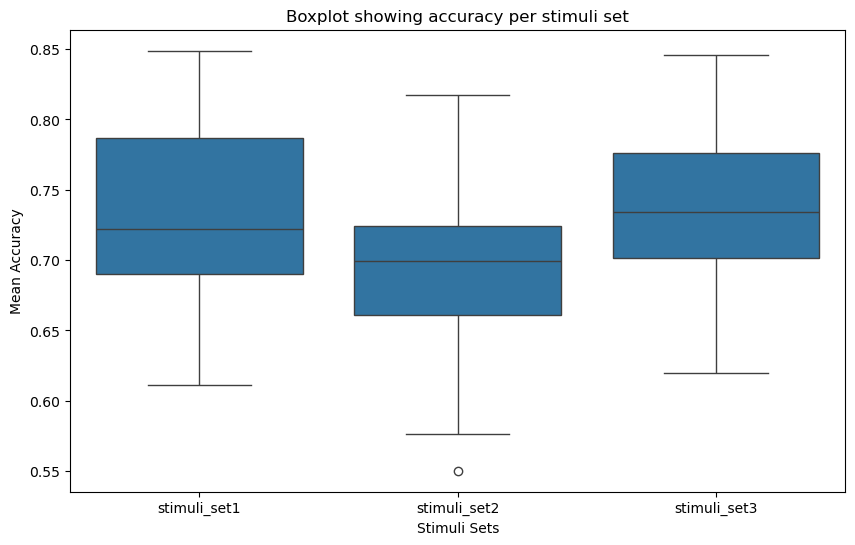

In [21]:
# Pingouin ANOVA
anova_result_acc_stimset = pg.anova(data=df, dv='acc_trial_concrete_cued', between='stimuli_set')
print('Pingouin Anova', anova_result_acc_stimset)

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_stimset['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference among the three stimuli sets.")
    tukey_stimset = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='stimuli_set', data=df)
    print(tukey_stimset)
else:
    print("The one-way ANOVA does not indicate a significant difference among the three stimuli sets.")


# Create an empty list to store grouped data for each participant
grouped_data_list = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)

# Concatenate the list of DataFrames into a single DataFrame
final_grouped_data = pd.concat(grouped_data_list)

# Reset the index to make 'subID' a regular column
final_grouped_data = final_grouped_data.reset_index()

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.boxplot(x='stimuli_set', y='acc_trial_concrete_cued', data=final_grouped_data)
plt.title('Boxplot showing accuracy per stimuli set')
plt.xlabel('Stimuli Sets')
plt.ylabel('Mean Accuracy')
plt.show()

# Thus, we would conclude that there is a statistically significant difference between the means of sets 1 and 2 and sets 2 and 3, 
# but not a statistically significant difference between the means of sets 1 and 3. 

In [22]:
tukey_stimset

,A,B,mean(A),mean(B),diff,se,T,p-tukey,hedges
0,stimuli_set1,stimuli_set2,0.731019,0.690228,0.040790,0.007149,5.706032,3.506350e-08,0.087916
1,stimuli_set1,stimuli_set3,0.731019,0.727965,0.003054,0.007289,0.418930,9.078071e-01,0.006714
2,stimuli_set2,stimuli_set3,0.690228,0.727965,-0.037737,0.007409,-5.093103,1.062079e-06,-0.080925


## Mean accuracy by condition, oneway ANOVA

Mean accuracy for all conditions: 0.7164765211640212
Mean accuracy per condition: items_presented
1    0.798363
2    0.694568
3    0.656498
Name: acc_trial_concrete_cued, dtype: float64
Anova Results             Source  ddof1  ddof2         F  p-unc     np2
0  items_presented      2  24189  207.1247    0.0  0.0168
The one-way ANOVA indicates a significant difference in accuracy among the three conditions.

   A  B  mean(A)  mean(B)    diff      se        T  p-tukey  hedges
0  1  2   0.7984   0.6946  0.1038  0.0072  14.3855      0.0  0.2331
1  1  3   0.7984   0.6565  0.1419  0.0072  19.6619      0.0  0.3139
2  2  3   0.6946   0.6565  0.0381  0.0072   5.2764      0.0  0.0799
There is a significant difference between groups 1.0 and 2.0.
Mean difference: 0.1037946428571429
There is a significant difference between groups 1.0 and 3.0.
Mean difference: 0.1418650793650793
There is a significant difference between groups 2.0 and 3.0.
Mean difference: 0.0380704365079364


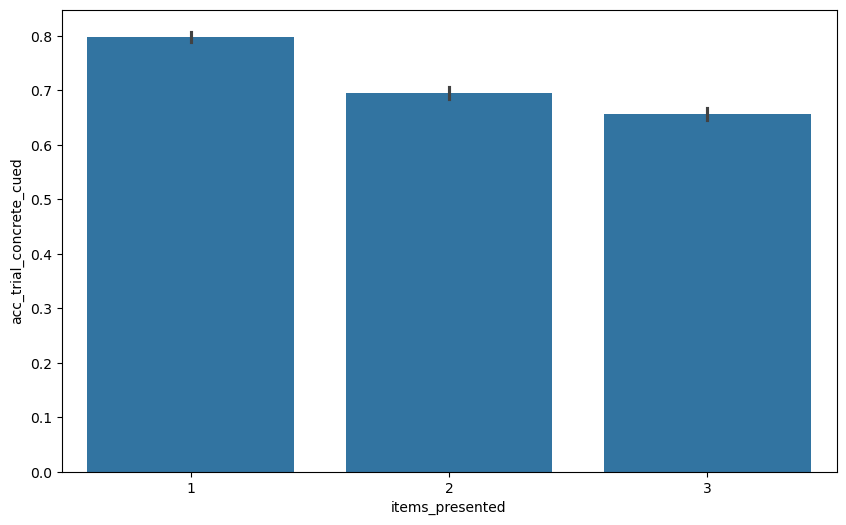

In [68]:

# does all three conditions in one and groups them by 'items_presented' which is the condition (can add .values at the end if I want only the answer values)
mean_acc = df['acc_trial_concrete_cued'].mean()
print("Mean accuracy for all conditions:", mean_acc)

mean_cond = df.groupby('items_presented')['acc_trial_concrete_cued'].mean()
print("Mean accuracy per condition:", mean_cond)

condition_means = mean_cond.tolist()
# why do I have the following line?
condition_labels = ['1', '2', '3']
# these turn out to be exactly the same size, I am a little suspicious that I indeed have exactly the same number of accuracy lines for every condition
# can remove this later, but might be interesting to check the number of samples per condition after I decide which participants to exclude
# len_sample_con1 = len(df[df['items_presented'] == 1])
# print('samples con1:', len_sample_con1)
# len_sample_con2 = len(df[df['items_presented'] == 2])
# print('samples con1:', len_sample_con2)
# len_sample_con3 = len(df[df['items_presented'] == 3])
# print('samples con1:', len_sample_con3)

# Pingouin ANOVA
anova_result_acc_items = pg.anova(data=df, dv='acc_trial_concrete_cued', between='items_presented')
print('Anova Results', anova_result_acc_items.round(4))

# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
if anova_result_acc_items['p-unc'].values[0] < alpha:
    print("The one-way ANOVA indicates a significant difference in accuracy among the three conditions.\n")
    tukey = pg.pairwise_tukey(dv='acc_trial_concrete_cued', between='items_presented', data=df)
    print(tukey.round(4))
    significant_pairs = tukey[tukey['p-tukey'] < 0.05]
    for index, row in significant_pairs.iterrows():
        print(f"There is a significant difference between groups {row['A']} and {row['B']}.")
        print(f"Mean difference: {row['mean(A)'] - row['mean(B)']}")
else:
    print("The one-way ANOVA does not indicate a significant difference in accuracy among the three conditions.")


plt.figure(figsize=(10,6))
sns.barplot(data=df, y='acc_trial_concrete_cued', x='items_presented')
plt.show()

## Accuraccy over time 

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64


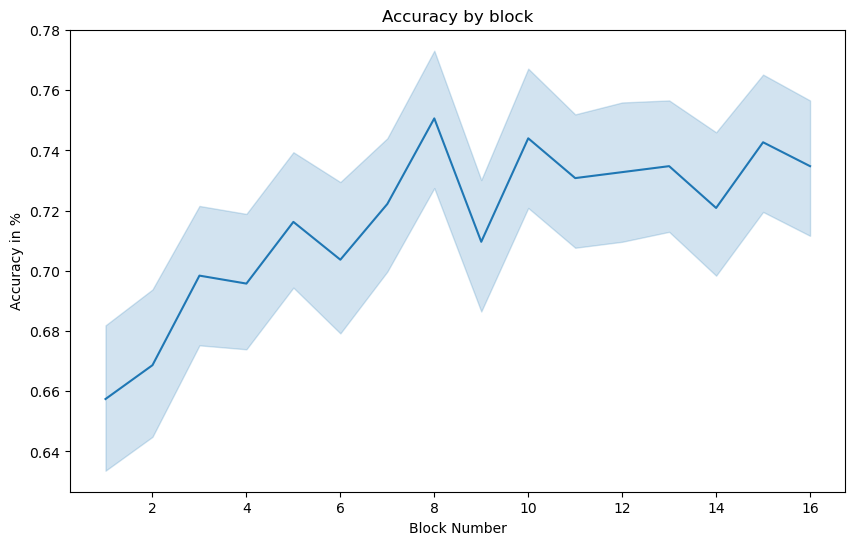

In [70]:
# ave_plot = matplotlib.pyplot.plot(ave_inflammation) -> general x/y plot
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='block_number', y='acc_trial_concrete_cued')
plt.xlabel('Block Number')  # Set the label for the x-axis
plt.ylabel('Accuracy in %')  # Set the label for the y-axis
plt.title('Accuracy by block')  # Set the title for the plot
plt.show()  # Display the plot

block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64


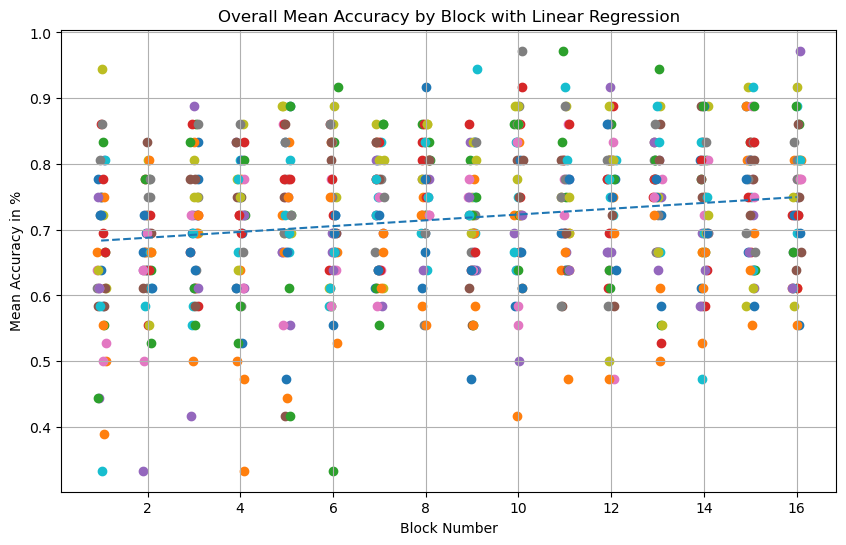

In [25]:
# Continue here

# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)

# Access accuracy data by block for each participant
accuracy_data_by_participant = {}

for participant_id in df['subID'].unique(): # should probably be good_partis instead
    participant_data = df[df['subID'] == participant_id]
    mean_accuracy_by_block = participant_data.groupby('block_number')['acc_trial_concrete_cued'].mean()
    accuracy_data_by_participant[participant_id] = mean_accuracy_by_block

# Create a scatterplot for each participant
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

jitter = 0.1 


for participant_id, accuracy_series in accuracy_data_by_participant.items():
    
    # Add jitter to the x-axis values
    x_values = accuracy_series.index + np.random.uniform(-jitter, jitter, len(accuracy_series))

    plt.scatter(x_values, accuracy_series, label=f'Participant {participant_id}', marker='o')
    
    # # Perform linear regression for each participant
    # slope, intercept, r_value, p_value, std_err = stats.linregress(accuracy_series.index, accuracy_series)
    # plt.plot(x_values, intercept + slope * x_values, label=f'LinReg (p={p_value:.4f})', linestyle='--')


plt.xlabel('Block Number')
plt.ylabel('Accuracy in %')
plt.title('Accuracy by Block for Each Participant')

plt.grid(True)


# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)
# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')

plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')

plt.grid(True)
plt.show()


plt.show()

,names,coef,se,T,pval,r2,adj_r2,CI[2.5%],CI[97.5%]
0,Intercept,0.6790,0.0062,109.0718,0.0,0.0019,0.0019,0.6668,0.6912
1,block_number,0.0044,0.0006,6.8481,0.0,0.0019,0.0019,0.0031,0.0057


/mnt/home/bielefeldt/miniconda3/envs/MultiEyeTemAnalysis/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


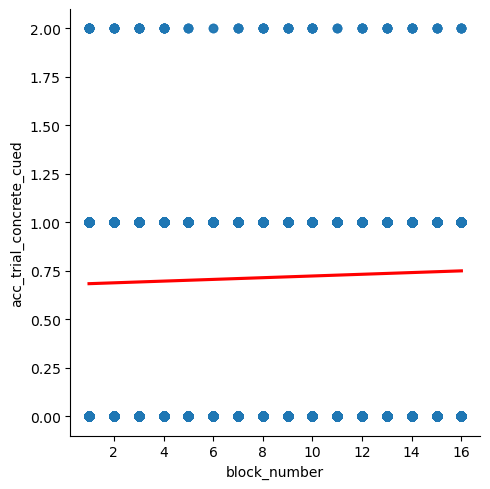

In [77]:
# The linear regression in this case looks good but the lmplot would need the meaned data per participant to work. Maybe the linear regression is then also wrong because I used the raw data??

lm_results = pg.linear_regression(df['block_number'], df['acc_trial_concrete_cued'])
display(lm_results.round(4))

sns.lmplot(x='block_number', y='acc_trial_concrete_cued', data=df, ci=None, line_kws={'color': 'red'})


block_number
1     0.657407
2     0.668651
3     0.698413
4     0.695767
5     0.716270
6     0.703704
7     0.722222
8     0.750661
9     0.709656
10    0.744048
11    0.730820
12    0.732804
13    0.734788
14    0.720899
15    0.742725
16    0.734788
Name: acc_trial_concrete_cued, dtype: float64
P-value: 0.000260934071776305


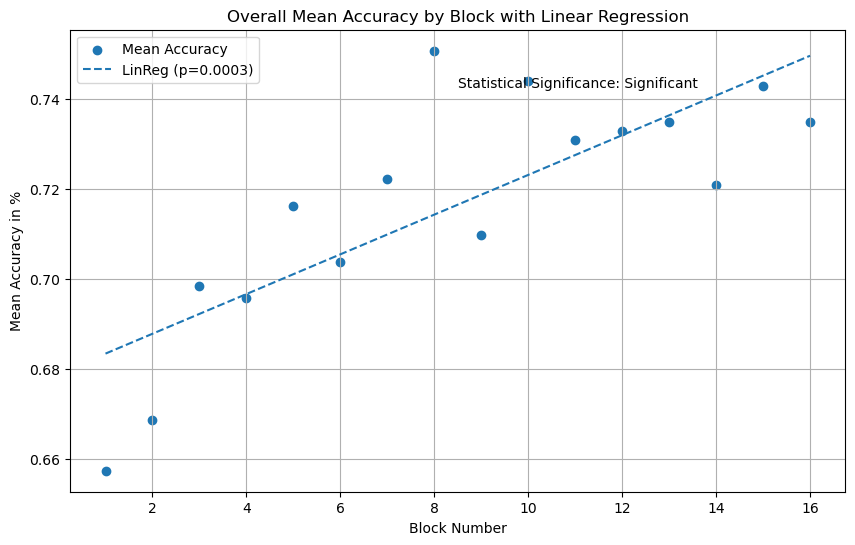

In [26]:
# Calculate the mean accuracy by block across all participants
mean_block_allp = df.groupby('block_number')['acc_trial_concrete_cued'].mean()
print(mean_block_allp)
# Perform a linear regression on the mean accuracy data
slope, intercept, r_value, p_value, std_err = stats.linregress(mean_block_allp.index, mean_block_allp)

# Create a scatterplot for the overall mean accuracy
plt.figure(figsize=(10, 6))  # Adjust the figure size as needed

plt.scatter(mean_block_allp.index, mean_block_allp, label='Mean Accuracy', marker='o')

# Plot the linear regression line
plt.plot(mean_block_allp.index, intercept + slope * mean_block_allp.index, label=f'LinReg (p={p_value:.4f})', linestyle='--')


print('P-value:', p_value)
# Add statistical significance annotation
if p_value < 0.05:
    significance = 'Significant'
else:
    significance = 'Not Significant'

plt.text(0.5, 0.9, f'Statistical Significance: {significance}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')


plt.xlabel('Block Number')
plt.ylabel('Mean Accuracy in %')
plt.title('Overall Mean Accuracy by Block with Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

## Accuracy depending on mnemonic distance? (position 1, 2 or 3)

Can only compare those in 
- position 1 (load 1)
- position 1 (load 2)
- position 1 (load 3)
- position 2 (load 2)
- position 2 (load 3)
- position 3 (load 3)

In [27]:
# # One way Anova
# # might want to group the data into either all data position 1, or group them seperately for the conditions as well
# # accuracy for position of item within the load conditions (mnemonic distance?, in position two and three they should be remembered better)

# # Make a dictionary 
# # in seconds 
# mne_dist_dict = {
#     "position1/load1": 3.5,
#     "position1/load2": 5.5,
#     "position1/load3": 6.5,
#     "position2/load2": 4.5,
#     "position2/load3": 5.5,
#     "position3/load3": 4.5
# }



# ## could actually calculate or at least list the actual distances between when the objects where shown and their test

# # just use the object at test in relation to its position during the learning period to check which position/laod
# # maybe rather use the object ID
# if df['stimuli_set'] == stimuli_set1:
#     if df['items_presented']==1
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load1 = 

#      if df['items_presented']==2
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load2 =

#      if df['items_presented']== 2
#         if object_test_id_cued == object_2_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos2_load2 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_1_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos1_load3 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_2_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos2_load3 = 

#      if df['items_presented']== 3
#         if object_test_id_cued == object_3_id

#         # need for elseif?
#         # what data to I ultimately want -> accuracy
#         accuracy_pos3_load3 = 

# # could this be done without the if items_presented? Does it matter if I sort by load first? Yes because the line afterwards
# # would otherwise be identical for some positions 

# # Distance Error
# # The distances between stim1 and its test are:
# ## meaning only in position 1 the distance in load 1 would be 0.5s for object timeout + 0.5s for fixation cross? (need to check in the lab)
# ## 3.5 ???


# # - Load1: 4 seconds (**error**!, it should be 1 + 3.5 seconds). ---> ## how did it end up being 4?
# # - Load2: 5.5 seconds (2+ 3.5 seconds).
# # - Load3: 6.5 seconds (3 + 3.5 seconds).


# Circular Stuff

## Oblique Effect

## Oblique Effect T-Test

mean per category:  Cardinal_Category
Cardinal    0.735101
Oblique     0.698051
Name: acc_trial_concrete_cued, dtype: float64
   Cardinal_Category  acc_trial_concrete_cued
0           Cardinal                 0.836066
1            Oblique                 0.745387
2           Cardinal                 0.725000
3            Oblique                 0.638514
4           Cardinal                 0.842657
..               ...                      ...
79           Oblique                 0.749164
80          Cardinal                 0.697917
81           Oblique                 0.729167
82          Cardinal                 0.537906
83           Oblique                 0.561873

[84 rows x 2 columns]


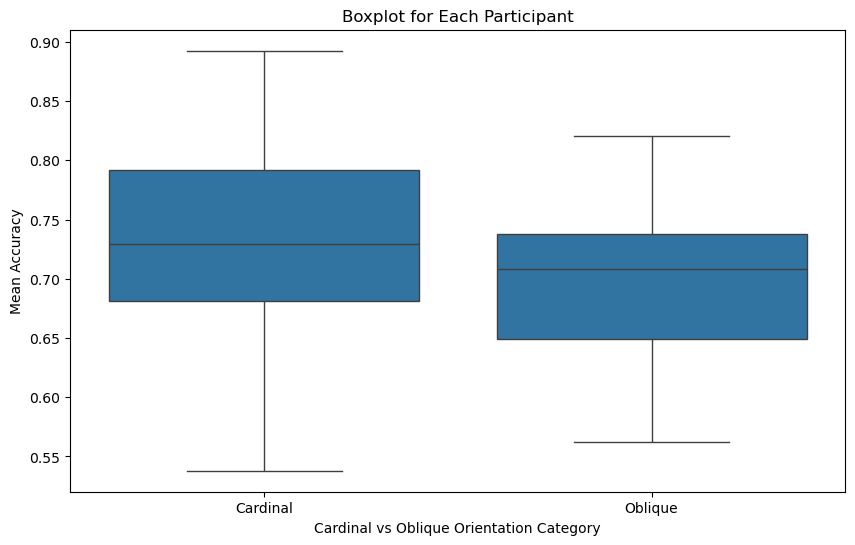

               T  dof alternative     p-val        CI95%  cohen-d   BF10  \
T-test  2.218838   82   two-sided  0.029261  [0.0, 0.07]  0.48419  1.892   

           power  
T-test  0.592072  
T-statistic: [2.21883787]
P-value: [0.02926109]
The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations


In [28]:

# orientations closest to the cardinal axes
orientation_subset_cardinal = [348.75, 11.25, 78.75, 101.25, 168.75, 191.25, 258.75, 281.25]


# Create a new column to indicate the categories
df['Cardinal_Category'] = df['object_cued_rot'].apply(lambda x: 'Cardinal' if x in orientation_subset_cardinal else 'Oblique')

# Calculate mean accuracy for each category
mean_per_category = df.groupby('Cardinal_Category')['acc_trial_concrete_cued'].mean()
print("mean per category: ", mean_per_category)

# Create an empty list to store grouped data for each participant
grouped_data_list = []

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean()
    
    # Append the grouped data to the list
    grouped_data_list.append(data)

# Concatenate the list of DataFrames into a single DataFrame
final_grouped_data_obli = pd.concat(grouped_data_list)

# Reset the index to make 'subID' a regular column
final_grouped_data_obli = final_grouped_data_obli.reset_index()
print(final_grouped_data_obli)

# Plot boxplots for each participant
plt.figure(figsize=(10, 6))
sns.boxplot(x='Cardinal_Category', y='acc_trial_concrete_cued', data=final_grouped_data_obli)
plt.title('Boxplot for Each Participant')
plt.xlabel('Cardinal vs Oblique Orientation Category')
plt.ylabel('Mean Accuracy')
plt.show()

# Statistics
# these have different results than the statistics below that I originally computed
# the final_grouped_data is data that has a mean per orientation for every participant
# below I used the mean per orientation across all participants (grouped_cardinal has 16 entries, final_grouped data (used here) has 640 entries (40 participants x 16 orientations))


oblique_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Oblique']['acc_trial_concrete_cued']
cardinal_data = final_grouped_data_obli[final_grouped_data_obli['Cardinal_Category'] == 'Cardinal']['acc_trial_concrete_cued']

# t_statistic, p_value = stats.ttest_ind(cardinal_data, oblique_data)
result_ttest_obli = pg.ttest(cardinal_data, oblique_data)
print(result_ttest_obli)

# Access specific properties
p_value = result_ttest_obli['p-val'].values
t_statistic = result_ttest_obli['T'].values

# Define the significance level (alpha)
alpha = 0.05

print("T-statistic:", t_statistic)
print("P-value:", p_value)


if p_value < alpha:
    print("The t-test indicates a significant difference between accuracy in oblique vs. cardinal orientations")
else:
    print("The t-test does not indicate a significant difference between accuracy in oblique vs. cardinal orientations")

# could add significance brackets. Easiest way would be to use statannotations but that lead to errors last time..




   Cardinal_Category      mean       std   subID  items_presented
0           Cardinal  0.895833  0.307080  Z16JQR                1
1            Oblique  0.781250  0.415569  Z16JQR                1
0           Cardinal  0.870370  0.337461  Z16JQR                2
1            Oblique  0.702381  0.459957  Z16JQR                2
0           Cardinal  0.742574  0.439397  Z16JQR                3
..               ...       ...       ...     ...              ...
1            Oblique  0.645833  0.502188  30K8XE                1
0           Cardinal  0.521277  0.523198  30K8XE                2
1            Oblique  0.581633  0.516201  30K8XE                2
0           Cardinal  0.505747  0.502865  30K8XE                3
1            Oblique  0.466667  0.501280  30K8XE                3

[252 rows x 5 columns]
                                Source      SS  ddof1  ddof2      MS  \
0                    Cardinal_Category  0.0818      1     41  0.0818   
1                      items_presented  

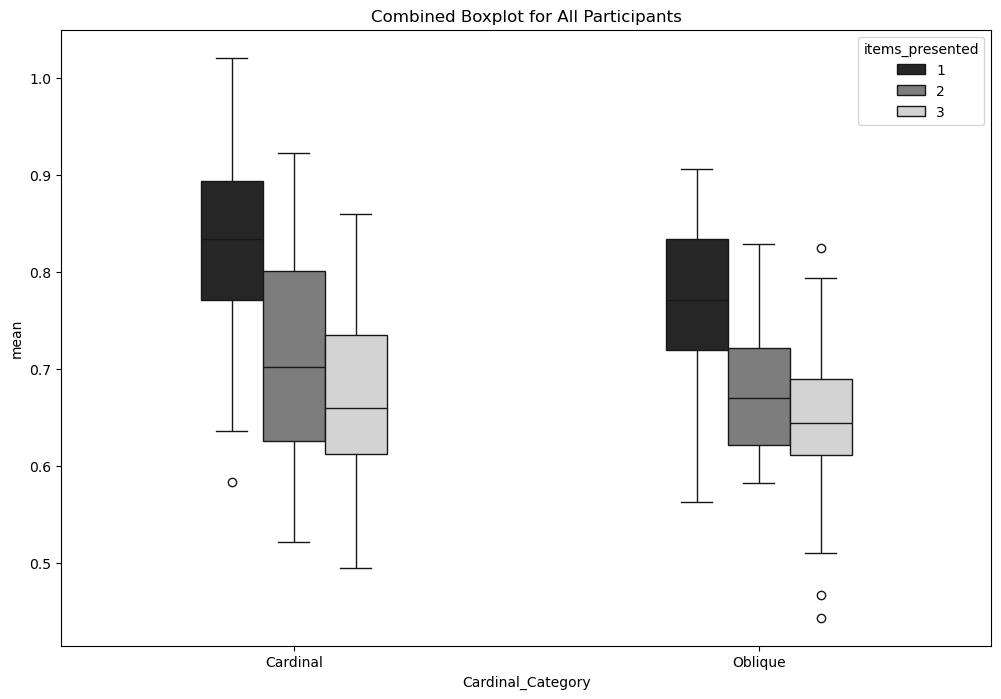

In [29]:
# comparing load conditions:

# participant_data_obli_con = []
# obli_con_list = []

all_p_obli_con = pd.DataFrame()

# Iterate through each participant in good_partis
for i in good_partis:
    # Group the data for the current participant
    # data = df[df['subID'] == i].groupby(['Cardinal_Category'])['acc_trial_concrete_cued'].mean()
    participant_data_obli_con = df.loc[df['subID'] == i, ['Cardinal_Category', 'acc_trial_concrete_cued', 'object_cued_rot', 'items_presented']]
    #participant_data1 = df.loc[(df['subID'] == i) & (df['items_presented'] == 1), 'acc_trial_concrete_cued']
        # condition 1
    #bp_con1 = participant_data.loc[participant_data['items_presented'] == 1].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con1 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 1].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con1['subID'] = i
    acc_obli_con1['items_presented'] = 1
    # condition 2
    #bp_con2 = participant_data.loc[participant_data['items_presented'] == 2].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con2 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 2].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con2['subID'] = i
    acc_obli_con2['items_presented'] = 2
    #bp_con3 = participant_data.loc[participant_data['items_presented'] == 3].groupby('object_cued_rot')['button_press_clockwise'].agg(['mean', 'std']).reset_index()
    acc_obli_con3 = participant_data_obli_con.loc[participant_data_obli_con['items_presented'] == 3].groupby('Cardinal_Category')['acc_trial_concrete_cued'].agg(['mean', 'std']).reset_index()
    acc_obli_con3['subID'] = i
    acc_obli_con3['items_presented'] = 3
    # Append the grouped data to the list
    #obli_con_list.append(participant_data_obli_con)

    
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con1])
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con2])
    all_p_obli_con = pd.concat([all_p_obli_con, acc_obli_con3])
print(all_p_obli_con)
    
# Box plot for all conditions for all participants
plt.figure(figsize=(12, 8))

# Subplot for all conditions
# sharey=True
plt.subplot() #221
sns.boxplot(x='Cardinal_Category', y='mean', hue='items_presented', data=all_p_obli_con, width=0.4, palette='dark:lightgray')
plt.title('Combined Boxplot for All Participants')

# Anova

# should I do a repeated measures anova here?
# run it on the df or the all_p_obli_c

# Perform ANOVA
alpha = 0.05
result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')

# the following two work but probably for all the wrong reasons
# should be a repeated measures anova, not pg.anova
# result_anova = pg.anova(data=all_p_obli_con, dv='mean', between=['Cardinal_Category', 'items_presented'])
# result_anova = pg.anova(data=final_grouped_data, dv='acc_trial_concrete_cued', between=['Cardinal_Category', 'items_presented'])

# Print ANOVA results
print(result_anova_obli_con.round(4))


In [30]:
# result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')

result_anova_single = pg.anova(data=all_p_obli_con, dv='mean', between=['Cardinal_Category'])
result_anova_single.round(4)

# meaning there is a difference between the cardinal categories, above I checked for an interaction between Cardinal Category and Condition
# should the results match the results below for the interaction?
# one is run with pg.anova and the other (above) with pg.rm_anova
# data used: all_p_obli_con in both cases -> 6 values per participant, 2 for each condition, and then 1 for every category each (caridnal vs oblique)



,Source,ddof1,ddof2,F,p-unc,np2
0,Cardinal_Category,1,250,7.3622,0.0071,0.0286


In [31]:
result_anova_obli_con = pg.rm_anova(data=all_p_obli_con, dv='mean', within=['Cardinal_Category', 'items_presented'], subject='subID')
result_anova_obli_con.round(4)

,Source,SS,ddof1,ddof2,MS,F,p-unc,p-GG-corr,ng2,eps
0,Cardinal_Category,0.0818,1,41,0.0818,13.8862,0.0006,0.0006,0.0420,1.0000
1,items_presented,0.9056,2,82,0.4528,142.0980,0.0000,0.0000,0.3270,0.8479
2,Cardinal_Category * items_presented,0.0077,2,82,0.0039,1.6561,0.1972,0.2018,0.0041,0.8403


In [32]:
display(all_p_obli_con.head(42))

,Cardinal_Category,mean,std,subID,items_presented
0,Cardinal,0.895833,0.307080,Z16JQR,1
1,Oblique,0.781250,0.415569,Z16JQR,1
0,Cardinal,0.870370,0.337461,Z16JQR,2
1,Oblique,0.702381,0.459957,Z16JQR,2
0,Cardinal,0.742574,0.439397,Z16JQR,3
1,Oblique,0.747253,0.436995,Z16JQR,3
0,Cardinal,0.781250,0.415569,C9A31N,1
1,Oblique,0.677083,0.470046,C9A31N,1
0,Cardinal,0.741935,0.463991,C9A31N,2
1,Oblique,0.616162,0.488794,C9A31N,2


### Oblique effect on polar plot

acc_df: object_cued_rot  items_presented
11.25            1                  0.851190
                 2                  0.718690
                 3                  0.705773
33.75            1                  0.791667
                 2                  0.731225
                 3                  0.701923
56.25            1                  0.785714
                 2                  0.642447
                 3                  0.593878
78.75            1                  0.797619
                 2                  0.731610
                 3                  0.637295
101.25           1                  0.815476
                 2                  0.713978
                 3                  0.629482
123.75           1                  0.734127
                 2                  0.666008
                 3                  0.629259
146.25           1                  0.763889
                 2                  0.701375
                 3                  0.633270
168.75        

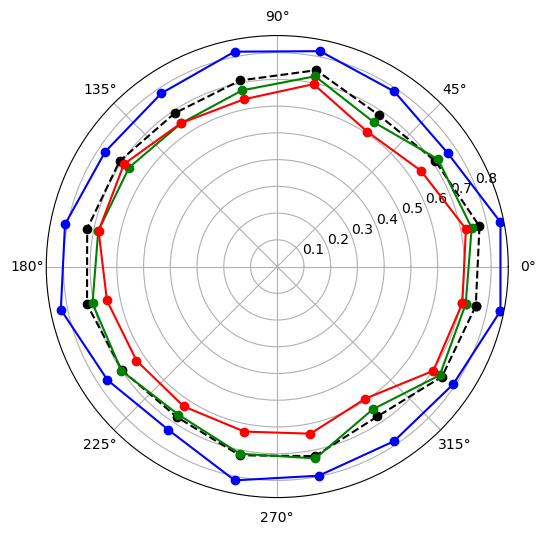

In [33]:
## Plotting the Oblique effect on a polar plot

spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])

acc_per_ori = df.groupby('object_cued_rot')['acc_trial_concrete_cued'].mean().values

acc_df = df.groupby(by=['object_cued_rot', 'items_presented'])['acc_trial_concrete_cued'].mean()
#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
oriacc1 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 1].to_numpy()
oriacc2 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 2].to_numpy()
oriacc3 = acc_df.loc[acc_df.index.get_level_values('items_presented') == 3].to_numpy()

print("acc_df:", acc_df)
print("oriacc1:", oriacc1)
print("oriacc2:", oriacc2)
print("oriacc3:", oriacc3)

# Create the polar plot
fig = plt.figure(figsize=(10,6))
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

acc_per_ori_circ = np.append(acc_per_ori, acc_per_ori[0])
oriacc1_circ = np.append(oriacc1, oriacc1[0])
oriacc2_circ = np.append(oriacc2, oriacc2[0])
oriacc3_circ = np.append(oriacc3, oriacc3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, acc_per_ori_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
# ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, oriacc1_circ, 'bo-')
ax.plot(-spacing_circ, oriacc2_circ, 'go-')
ax.plot(-spacing_circ, oriacc3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


## Cardinal Repulsion

### Cardinal Repulsion Bias Plot (?)
For the polar plot I can either: plt.axes(projection='polar'), plt.polar() or fig = plt.figure() + ax = fig.add_subplot(111, projection='polar')

I think I started the following bullet points when simultaneosly reading the Memoreye paper
Calculating whether
1) a repulsion bias occured (bias away from the cardinal axes)
2)

MBP: [0.57948718 0.46143791 0.43177324 0.40267559 0.55404487 0.47514911
 0.43709468 0.38682322 0.61615487 0.57245431 0.52921865 0.49933599
 0.62897766 0.57306397 0.51411687 0.40576794]
MBP1: [0.55357143 0.48611111 0.43253968 0.38888889 0.56150794 0.43055556
 0.41269841 0.46031746 0.62103175 0.55753968 0.52777778 0.50396825
 0.63095238 0.56944444 0.52380952 0.44047619]
MBP2: [0.59152216 0.46640316 0.43594646 0.42743539 0.54623656 0.51185771
 0.45776031 0.36926148 0.60961538 0.57333333 0.4990099  0.50101833
 0.63817097 0.58401639 0.51287129 0.37575758]
MBP3: [0.59217877 0.43269231 0.42653061 0.39139344 0.55378486 0.48296593
 0.44045369 0.33333333 0.61814346 0.58648111 0.56031128 0.49315068
 0.61702128 0.56592292 0.50583658 0.4004065 ]


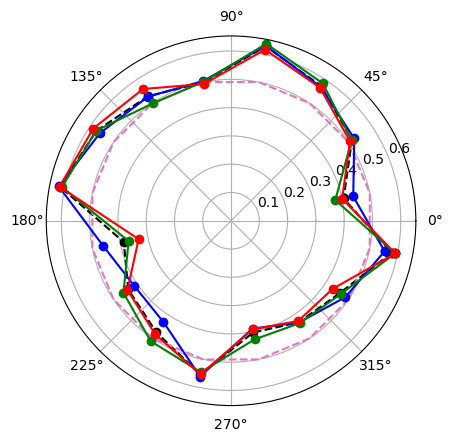

In [34]:
# Original Plot

# since I transformed the data to radians, the data is no longer between 0 and 1 but between 0.001 and 0.2 (I think). Therefore the tick labels on the plot are not reflecting the actual data. In the plot below (next code cell) I managred to transform the data back but the it looks like the 
# maximum value of 0.63 is never reached so something might be off. 
# Also the plot still looks like the opposite of what Juan was plotting. WHY???
# maybe I need to double check where the starting point of my data is. If the first point would be plotted one orientation too far into the clockwise direction it would look very different. I doubt this is what is going on though since the overall shape looks pretty good
# could I use degrees instead of radians?

# spacing is what is usually called theta in the polar plots. not sure if this is correct or just a butched way that works, 
# could also be coded using np.arange of divisions of pi, which is more common practice but harder to read
spacing = np.arange(11.25, 360, 22.5)
spacing_rad = np.radians(spacing)

## change the above line to make it so that positive is going anticlockwise. Apparently theta is always going anticlockwise

# making it a full circle
spacing_circ = np.append(spacing_rad, spacing_rad[0])


#print(mbp_df)
#-> this output looks right but looking at the variable mbp_df in the data viewer looks weird
# -> this returns a dataframe called mbp_df that is the same size as df but is sorted by object_cued_rot and within each object_cued_rot it is then sorted by items_presented

# seperate by con
# why use the get_level_values (could probably be done easier?)
mbp_per_ori = df.groupby('object_cued_rot')['button_press_clockwise'].mean().values
mbp_df = df.groupby(by=['object_cued_rot', 'items_presented'])['button_press_clockwise'].mean()
mbp1 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 1].to_numpy()
mbp2 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 2].to_numpy()
mbp3 = mbp_df.loc[mbp_df.index.get_level_values('items_presented') == 3].to_numpy()


print("MBP:", mbp_per_ori)
print("MBP1:", mbp1)
print("MBP2:", mbp2)
print("MBP3:", mbp3)

# Create the polar plot
fig = plt.figure()
# maybe change the following line to plt.axes(projection='polar')
ax = fig.add_subplot(111, projection='polar')

#Repeating the last data point to make it a full circle
# mbp_rad = np.append(mbp_rad, mbp_rad[0])
# mbp1_rad = np.append(mbp1_rad, mbp1_rad[0])
# mbp2_rad = np.append(mbp2_rad, mbp2_rad[0])
# mbp3_rad = np.append(mbp3_rad, mbp3_rad[0])

mbp_circ = np.append(mbp_per_ori, mbp_per_ori[0])
mbp1_circ = np.append(mbp1, mbp1[0])
mbp2_circ = np.append(mbp2, mbp2[0])
mbp3_circ = np.append(mbp3, mbp3[0])

# Plot the data for the general mbp
ax.plot(-spacing_circ, mbp_circ, 'ko--')

unbiased_assumption = np.full(17, 0.5)

# # Plot the data for the three conditions individually
# at the moment using -spacing_rad to make the data go in the correct (anticlockwise direction)
ax.plot(-spacing_circ, unbiased_assumption, color='tab:pink', linestyle='dashed')
ax.plot(-spacing_circ, mbp1_circ, 'bo-')
ax.plot(-spacing_circ, mbp2_circ, 'go-')
ax.plot(-spacing_circ, mbp3_circ, 'ro-')


# Set plot attributes (-> labels and shit)
plt.legend
# Show the plot
plt.show()


In [35]:
# what did I do this for, this seems pretty perfect actually
# ah yes, with the multiple keys within the groupby, I need to specifically use get_group with all three exact 
# the reset_index at the end makes it a pandas dataframe again??? so weird. sometimes reset_index makes it a series and here
# a dataframe again?

mbp_df_2 = df.groupby(by=['object_cued_rot', 'items_presented', 'subID'])['button_press_clockwise'].mean().reset_index()
mbp_df_con = mbp_df_2.groupby('items_presented')
display(mbp_df_2)
display(mbp_df_con)
type(mbp_df_2)

# for key, item in mbp_df_2:
#     print(mbp_df_2.get_group(key), "\n\n")

# mbp_df_2.groups
# using mean() at the end of the groupby disables the groupby function


con_1 = mbp_df_con.get_group((1))
display(con_1)

# # loc[(mbp_df_2['object_cued_rot'] == '11.25'), ['button_press_clockwise']]
con_2 = mbp_df_con.get_group((2))
con_3 = mbp_df_con.get_group((3))

,object_cued_rot,items_presented,subID,button_press_clockwise
0,11.25,1,1L974Q,0.500000
1,11.25,1,1UVQEK,0.583333
2,11.25,1,30K8XE,0.500000
3,11.25,1,35T018,0.750000
4,11.25,1,45G1TX,0.250000
...,...,...,...,...
2011,348.75,3,XG7QAG,0.200000
2012,348.75,3,XXRRPP,0.545455
2013,348.75,3,Z16JQR,0.230769
2014,348.75,3,Z632AK,0.200000


,object_cued_rot,items_presented,subID,button_press_clockwise
0,11.25,1,1L974Q,0.500000
1,11.25,1,1UVQEK,0.583333
2,11.25,1,30K8XE,0.500000
3,11.25,1,35T018,0.750000
4,11.25,1,45G1TX,0.250000
...,...,...,...,...
1927,348.75,1,XG7QAG,0.166667
1928,348.75,1,XXRRPP,0.583333
1929,348.75,1,Z16JQR,0.583333
1930,348.75,1,Z632AK,0.500000


In [36]:
# Grouping the data by the necessary keys and producing a mean for button press clockwise for every condition and orientation and subject ID

df_grouped = df.groupby(['subID', 'items_presented','object_cued_rot']).agg({'button_press_clockwise':(['mean'])}, as_index=False)
display(df_grouped)

# Grouping by Condition
condition_grps = df_grouped.groupby('items_presented', as_index=False)
# Condition 1
condition_1 = condition_grps.get_group(1).reset_index()
# Condition 2
condition_2 = condition_grps.get_group(2).reset_index()
# Condition 3
condition_3 = condition_grps.get_group(3).reset_index()


button_press_clockwise
                                                         mean
subID  items_presented object_cued_rot                       
1L974Q 1               11.25                         0.500000
                       33.75                         0.166667
                       56.25                         0.500000
                       78.75                         0.250000
                       101.25                        0.416667
...                                                       ...
ZGV9KP 3               258.75                        0.461538
                       281.25                        0.666667
                       303.75                        0.411765
                       326.25                        0.500000
                       348.75                        0.272727

[2016 rows x 1 columns]

In [37]:
# all conditions

all_differences_all_con = []
subIDs = []
for i in good_partis: 
    df_grouped_all_con = df.groupby(['subID', 'object_cued_rot']).agg({'button_press_clockwise':(['mean'])}, as_index=False).reset_index()
    participant_grps = df_grouped_all_con.groupby('subID', as_index=False)
    participant_data = participant_grps.get_group(i)

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_all_con.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_all_con = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_all_con})
display(differences_df_all_con)

ttest_results = pg.ttest(differences_df_all_con['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

NameError: name 'differences' is not defined

In [ ]:
all_differences_con1 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_1.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()
    
        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con1.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con1 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con1})
display(differences_df_con1)

ttest_results = pg.ttest(differences_df_con1['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

In [ ]:
all_differences_con2 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_2.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con2.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con2 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con2})
display(differences_df_con2)

ttest_results = pg.ttest(differences_df_con2['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

In [ ]:
all_differences_con3 = []
subIDs = []
for i in good_partis: 
    participant_grp = condition_3.groupby('subID', as_index=False)
    participant_data = participant_grp.get_group(i)
    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        differences.append(difference)

    mean_difference = np.mean(differences)
    all_differences_con3.append(mean_difference)
    #trying to append the subID here within the loop to the difference value, need to go into a new column
    
    subIDs.append(i)


#suggestion from chatGPT, commented out the stuff below 
differences_df_con3 = pd.DataFrame({'subID': subIDs, 'Mean_Difference': all_differences_con3})
display(differences_df_con3)

ttest_results = pg.ttest(differences_df_con3['Mean_Difference'], 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))

### ANOVA comparing the cardinal repulsion in the load conditions

In [ ]:
# Perform one-way ANOVA

load_1_data = differences_df_con1['Mean_Difference']
load_2_data = differences_df_con2['Mean_Difference']
load_3_data = differences_df_con3['Mean_Difference']

# Note: f_oneway performs a one-way ANOVA on multiple samples
#returns two variables called statistic and p_value
f_statistic, p_value = stats.f_oneway(load_1_data, load_2_data, load_3_data)#

# should I also (or even do this first) calculate whether the individual conditions are significantly different from the general mean
# Define the significance level (alpha)
alpha = 0.05

# Check if the p-value is less than alpha to determine significance
print("ANOVA Results:")
print("F-statistic:", f_statistic)
print("p-value:", p_value)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")


In [ ]:
# Pingouin ANOVA

differences_df_con1['items_presented'] = 1
differences_df_con2['items_presented'] = 2
differences_df_con3['items_presented'] = 3

combined_df2 = pd.concat([differences_df_con1, differences_df_con2, differences_df_con3])
display(combined_df2)

anova_results = pg.anova(data=combined_df2, dv='Mean_Difference', between='items_presented')

# Display ANOVA results
display(anova_results)

if p_value < alpha:
    print("The ANOVA test indicates a significant difference among the load conditions.")
else:
    print("The ANOVA test does not indicate a significant difference among the load conditions.")

plt.figure(figsize=(10, 6))  # Set the figure size

# Create a boxplot
sns.boxplot(data=combined_df2, x='items_presented', y='Mean_Difference')
plt.xlabel('Items Presented')
plt.ylabel('Mean Cardinal Repulsion at Cardinal Positions')
plt.title('Boxplot of Cardinal Repulsion Indices for Different Conditions')
plt.show()

In [ ]:
oris = []
oris_value = 11.25

while oris_value <= 360:
    oris.append(oris_value)
    oris_value = oris_value + 360/16

print(oris)

# oris_unique = df['object_cued_rot'].unique()
# oris_unique = np.sort(oris_unique)
oris_unique = np.sort(df['object_cued_rot'].unique())
oris_unique


In [ ]:
# # Trying to do the Cardinal Bias in one block
# conditions = df['items_presented'].unique()

# for condition in conditions:
#     condition_2 = condition_grps.get_group(2).reset_index()

## Cardinal Bias Index different version - same thing

In [ ]:
#using seaborn and pingouin


# I want to calculate the difference between the two orientations closest to the cardinal axes and take the average of those
# four numbers 
# either the hypothesis is that the difference between the two points is lower than zero or higher than zero (?)

# x0 - y0

# x90 - y90

# x180 - y180

# x270 - y270

# mean der 4 zahlen

# - -> 1 index pro proband

# erwartung: höher als 0

# testing mit 1-sample-t-test against 0
result_dict = {}
result_list_index = []

for i in good_partis:
    
    participant_data = df[df['subID']==i]

    # Create an empty list to store values for each participant
    participant_values_x = []
    participant_values_y = []

    for ori in [11.25, 101.25, 191.25, 281.25]:
        participant_data_ori_x = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_x.append(participant_data_ori_x)
    
    for ori in [348.75, 78.75, 168.75, 258.75]:
        participant_data_ori_y = participant_data.loc[participant_data['object_cued_rot'] == ori, ['object_cued_rot', 'button_press_clockwise']].mean()
      
        # Append the 'button_press_clockwise' values to the list
        participant_values_y.append(participant_data_ori_y)
        display(participant_values_y)
        #index = (participant_values_x - participant_values_y)
        #result_list_index.append(index)
    # participant_index = participant_values_x - participant_values_y

    # Store the lists of values in the dictionary with participant ID as the key
    result_dict[i] = {'participant_data_ori_x': participant_values_x, 'participant_data_ori_y': participant_values_y, } # 'participant_index': participant_index

        
# Print or use the result_dict as needed
# for participant_id, values_dict in result_dict.items():
#     print(f"Participant {participant_id}:")
#     print("participant_data_ori_x:", values_dict['participant_data_ori_x'])
#     print("participant_data_ori_y:", values_dict['participant_data_ori_y'])

display(result_list_index)

In [ ]:
display(type(participant_values_y))
display(type(participant_data_ori_y))

In [ ]:
# Is this all conditions?

mean_differences = []

for i in good_partis: 
    participant_data = df[df['subID'] == i]

    differences = []

    # Define the pairs of orientations for subtraction
    orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

    for ori_x, ori_y in orientation_pairs:
        value_x = participant_data.loc[participant_data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
        value_y = participant_data.loc[participant_data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

        # Calculate the difference and append to the list
        difference =  value_x - value_y
        
        differences.append(difference)

    mean_difference = np.mean(differences)
    print(i, mean_difference)

    mean_differences.append(mean_difference)


# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
ttest_results = pg.ttest(mean_differences, 0)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
display(ttest_results.round(4))


z_part_result = (0.000000 + 0.126042 + 0.231215)/3
display(z_part_result)
# 

In [ ]:
test = df['items_presented'].unique()
display(test)

In [ ]:
# Code by Dilara

mean_differences = np.empty([len(good_partis),len(df['items_presented'].unique())])

for j,load in enumerate(df['items_presented'].unique()):

    for i in good_partis: 
        data = df[(df['subID'] == i) & (df['items_presented'] == load)]
        differences = []

        # Define the pairs of orientations for subtraction
        orientation_pairs = [(11.25, 348.75), (101.25, 78.75), (191.25, 168.75), (281.25, 258.75)]

        for ori_x, ori_y in orientation_pairs:
            value_x = data.loc[data['object_cued_rot'] == ori_x, 'button_press_clockwise'].mean()
            value_y = data.loc[data['object_cued_rot'] == ori_y, 'button_press_clockwise'].mean()

            # Calculate the difference and append to the list
            difference =  value_x - value_y
            
            differences.append(difference)
    display(mean_differences)
    mean_differences[i,j] = np.mean(differences)
    # mean_differences[i,j]

# the ttest works on differences, but not on mean differences. Why?
# since it seems to be an issue that there is no variance, maybe I need the full data per participant  
rm_anova_results = pg.rm_anova(data=mean_differences)
# print(f"T-Test results for Participant {i}:\n{ttest_results}")
print(f"T-Test for each Participant:\n{ttest_results}")

In [ ]:
type(mean_differences)

In [ ]:
# can try and continue here?

for i in good_partis:
    filt_ori_pp = (df['subID'] == i) & (df['items_presented'] == 1)
    participant_data = df.loc[filt_ori_pp, ['subID', 'items_presented', 'object_cued_rot', 'acc_trial_concrete_cued']]
    # print(participant_data)
    groupby_by_object = participant_data.groupby(['object_cued_rot'])
    display(groupby_by_object.get_group(11.25))

In [ ]:
# values_y_array = np.array(participant_values_y[])
# values_x_array = np.array(participant_values_x)    
# print(values_y_array)
# print(values_x_array)
# result_index = values_y_array - values_x_array
# print(result_index)
df1 = pd.DataFrame({'A': [1, 2, 3]})
df2 = pd.DataFrame({'B': [4, 5, 6]})
participant_values_x = [df1, df2]
print('x_values', participant_values_x)

df3 = pd.DataFrame({'A': [7, 8, 9]})
df4 = pd.DataFrame({'B': [10, 11, 12]})
participant_values_y = [df3, df4]
print('y_values', participant_values_y)

# Using zip to pair DataFrames from participant_values_x and participant_values_y
paired_dataframes = zip(participant_values_x, participant_values_y)


# Printing the paired_dataframes
for x, y in paired_dataframes:
    print("DataFrame X:")
    print(x)
    print("DataFrame Y:")
    print(y)
    print("-----------")

In [ ]:
# What is the difference between:
data1 = df[df['subID'] == i].groupby(['stimuli_set'])['acc_trial_concrete_cued'].mean()
print(data1)
# and
data2 = df.loc[df['subID'] == i, ['stimuli_set', 'acc_trial_concrete_cued']].mean()
print(data2)

In [ ]:
data1_all = []
# data1
data1_all.append(data1)
print(data1_all)

In [ ]:
data2

In [ ]:
len(df)